# 🧠 EmpathicSchool — Notebook 2: Modeling (PyTorch + CUDA)

**GPU:** NVIDIA RTX 4060 Laptop · CUDA 12.1 · PyTorch 2.5

| Section | Output |
|---------|--------|
| 4 | Model architecture (3 variants) |
| 6 | LOSO CV — per-fold Acc, F1, Precision, Recall |
| 7 | Mean ± std summary |
| 8 | Aggregated confusion matrix |
| 9 | Window vs Session accuracy |
| 10 | Per-subject bar chart |
| 11 | Training curves |
| 12 | **Ablation study** |
| 13 | Parameters & training time |
| 14 | Feature saliency |


---
## 0 · Install


In [1]:
# import sys
# !{sys.executable} -m pip install scikit-learn pandas matplotlib seaborn --quiet
# print('Done.')


---
## 1 · Config


In [2]:
import os

BASE_DIR       = r'C:\Users\yomna.000\Downloads\grad\new dataset\EmpathicSchool'
PREPARED_DIR   = os.path.join(BASE_DIR, 'prepared')
OUTPUT_DIR     = os.path.join(BASE_DIR, 'outputs')
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, 'checkpoints')
RESULTS_DIR    = os.path.join(OUTPUT_DIR, 'results')
PLOTS_DIR      = os.path.join(RESULTS_DIR, 'plots')
for d in [CHECKPOINT_DIR, RESULTS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

CNN_FILTERS  = [64, 128, 256]
CNN_KERNEL   = 3
CNN_POOL     = 2
LSTM_UNITS   = [128, 64]
DENSE_UNITS  = 64
DROPOUT_RATE = 0.3
NUM_CLASSES  = 2
CLASS_NAMES  = ['not-stressed', 'stressed']

BATCH_SIZE       = 64
MAX_EPOCHS       = 100
LEARNING_RATE    = 5e-4
LR_PATIENCE      = 10
EARLY_STOP_PAT   = 20
WEIGHT_DECAY     = 1e-4
VALIDATION_SPLIT = 0.15
VOTING_METHOD    = 'soft'
RANDOM_SEED      = 42

print('Config loaded.')


Config loaded.


---
## 2 · Imports & GPU


In [3]:
import random, time, json, warnings
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau

from sklearn.preprocessing     import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics            import (accuracy_score, f1_score,
                                         precision_score, recall_score,
                                         confusion_matrix)

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available(): torch.cuda.manual_seed_all(RANDOM_SEED)

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

print(f'PyTorch : {torch.__version__}')
print(f'Device  : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')


PyTorch : 2.5.1+cu121
Device  : cuda
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM    : 8.6 GB


---
## 3 · Load Data


In [4]:
X      = np.load(os.path.join(PREPARED_DIR,'X.npy'))
y      = np.load(os.path.join(PREPARED_DIR,'y.npy'))
groups = np.load(os.path.join(PREPARED_DIR,'groups.npy'))
with open(os.path.join(PREPARED_DIR,'meta.json')) as f:
    meta = json.load(f)

feature_names  = meta['feature_names']
subject_labels = meta['subjects']
N, T, F = X.shape

print(f'X      : {X.shape}  (windows x timesteps x features)')
print(f'y      : {y.shape}')
print(f'Groups : {groups.shape}  ({len(np.unique(groups))} subjects)')
print(f'Features ({F}): {feature_names}')
for c, name in enumerate(['not-stressed','stressed']):
    n = int((y==c).sum())
    print(f'  Class {c} ({name:12s}): {n:5d}  ({100*n/len(y):.1f}%)')


X      : (1116, 240, 13)  (windows x timesteps x features)
y      : (1116,)
Groups : (1116,)  (20 subjects)
Features (13): ['hr', 'eda', 'temp', 'acc_x', 'acc_y', 'acc_z', 'acc_mag', 'angry', 'disgust', 'fear', 'happy', 'sad', 'surprise']
  Class 0 (not-stressed):   574  (51.4%)
  Class 1 (stressed    ):   542  (48.6%)


---
## 4 · Model Definition

Three variants — all share the same CNN backbone:

| Variant | LSTM direction | Attention |
|---------|---------------|----------|
| `cnn_lstm` | Unidirectional | No |
| `cnn_bilstm` | Bidirectional | No |
| `cnn_bilstm_attn` | Bidirectional | Yes |


In [5]:
class StressNet(nn.Module):
    """
    CNN + LSTM/BiLSTM + optional Self-Attention for stress classification.
    Input: (batch, time_steps, n_features)  — channels-last
    """
    def __init__(self, n_features, n_classes=3, variant='cnn_bilstm_attn'):
        super().__init__()
        self.variant = variant
        bidirectional = variant in ('cnn_bilstm', 'cnn_bilstm_attn')
        use_attn      = variant == 'cnn_bilstm_attn'

        # ── CNN blocks (1D along time axis) ──────────────────────────────
        cnn_layers = []
        in_ch = n_features
        for out_ch in CNN_FILTERS:
            cnn_layers += [
                nn.Conv1d(in_ch, out_ch, kernel_size=CNN_KERNEL, padding=CNN_KERNEL//2),
                nn.BatchNorm1d(out_ch),
                nn.ReLU(),
                nn.Dropout(DROPOUT_RATE),
                nn.MaxPool1d(CNN_POOL),
            ]
            in_ch = out_ch
        self.cnn = nn.Sequential(*cnn_layers)

        # ── BiLSTM / LSTM blocks ─────────────────────────────────────────
        self.lstms = nn.ModuleList()
        self.drops  = nn.ModuleList()
        lstm_in = CNN_FILTERS[-1]
        for i, units in enumerate(LSTM_UNITS):
            self.lstms.append(nn.LSTM(
                lstm_in, units,
                batch_first=True,
                bidirectional=bidirectional,
                dropout=DROPOUT_RATE if i < len(LSTM_UNITS)-1 else 0))
            self.drops.append(nn.Dropout(DROPOUT_RATE))
            lstm_in = units * (2 if bidirectional else 1)

        # ── Self-Attention ────────────────────────────────────────────────
        self.use_attn = use_attn
        if use_attn:
            self.attn_W = nn.Linear(lstm_in, lstm_in, bias=False)
            self.attn_v = nn.Linear(lstm_in, 1,       bias=False)

        # ── Dense head ───────────────────────────────────────────────────
        self.head = nn.Sequential(
            nn.Linear(lstm_in, DENSE_UNITS),
            nn.BatchNorm1d(DENSE_UNITS),
            nn.ReLU(),
            nn.Dropout(DROPOUT_RATE),
            nn.Linear(DENSE_UNITS, n_classes),
        )

    def forward(self, x):
        # x: (B, T, F)
        x = x.permute(0, 2, 1)          # → (B, F, T) for Conv1d
        x = self.cnn(x)
        x = x.permute(0, 2, 1)          # → (B, T', C) for LSTM

        for lstm, drop in zip(self.lstms, self.drops):
            x, _ = lstm(x)
            x = drop(x)

        if self.use_attn:
            w = torch.softmax(self.attn_v(torch.tanh(self.attn_W(x))), dim=1)
            x = (w * x).sum(dim=1)       # → (B, C)
        else:
            x = x[:, -1, :]              # last timestep → (B, C)

        return self.head(x)              # → (B, n_classes)


# ── Architecture summary ──────────────────────────────────────────────────
print('=' * 60)
print('ARCHITECTURE SUMMARY — CNN + BiLSTM + Attention')
print('=' * 60)
preview = StressNet(F, NUM_CLASSES, 'cnn_bilstm_attn').to(DEVICE)
total   = sum(p.numel() for p in preview.parameters())
train_p = sum(p.numel() for p in preview.parameters() if p.requires_grad)
print(preview)
print(f'\nTotal params     : {total:,}')
print(f'Trainable params : {train_p:,}')
# Dry run
dummy = torch.zeros(2, T, F).to(DEVICE)
out   = preview(dummy)
print(f'Output shape     : {out.shape}  (batch x {NUM_CLASSES} classes)')
del preview, dummy
torch.cuda.empty_cache()


ARCHITECTURE SUMMARY — CNN + BiLSTM + Attention
StressNet(
  (cnn): Sequential(
    (0): Conv1d(13, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
    (11): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): Dropout(p=0.3, inplace=False)
    (14): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstms): Modu

---
## 5 · Normaliser & Majority Vote


In [6]:
class WindowNormalizer:
    """StandardScaler over (N, T, F) — fit on train, transform test."""
    def __init__(self):
        self.scaler = StandardScaler()
    def fit_transform(self, X):
        N, T, F = X.shape
        return self.scaler.fit_transform(X.reshape(N*T, F)).reshape(N, T, F).astype(np.float32)
    def transform(self, X):
        N, T, F = X.shape
        return self.scaler.transform(X.reshape(N*T, F)).reshape(N, T, F).astype(np.float32)


def majority_vote(probs, method=VOTING_METHOD):
    """probs: (n_windows, n_classes) numpy array."""
    if method == 'soft':
        return int(np.argmax(probs.sum(axis=0)))
    return int(np.argmax(np.bincount(probs.argmax(axis=1), minlength=NUM_CLASSES)))


print('Normaliser and majority vote defined.')


Normaliser and majority vote defined.


---
## 6 · LOSO Training Loop


In [7]:
def train_fold(X, y, groups, subj_idx, subj_name,
               fold_num, total_folds, variant='cnn_bilstm_attn'):

    tr = np.where(groups != subj_idx)[0]
    te = np.where(groups == subj_idx)[0]
    X_tr, y_tr = X[tr], y[tr]
    X_te, y_te = X[te], y[te]

    # Normalise
    norm = WindowNormalizer()
    X_tr = norm.fit_transform(X_tr)
    X_te = norm.transform(X_te)

    # Train/val split
    n_val   = max(1, int(len(X_tr) * VALIDATION_SPLIT))
    n_train = len(X_tr) - n_val
    idx     = np.random.permutation(len(X_tr))
    tr_idx, val_idx = idx[:n_train], idx[n_train:]

    def to_loader(Xa, ya, shuffle=False, drop_last=False):
        ds = TensorDataset(torch.from_numpy(Xa).float(),
                            torch.from_numpy(ya).long())
        return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                          pin_memory=True, num_workers=0, drop_last=drop_last)
    
    tr_loader  = to_loader(X_tr[tr_idx],  y_tr[tr_idx],  shuffle=True,  drop_last=True)
    val_loader = to_loader(X_tr[val_idx], y_tr[val_idx], shuffle=False, drop_last=False)

    # Class weights
    cw  = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_tr)
    cw  = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=cw)

    model = StressNet(X_tr.shape[2], NUM_CLASSES, variant).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(),
                                  lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer, mode='min',
                                   factor=0.5, patience=LR_PATIENCE)

    best_val_loss = float('inf')
    patience_cnt  = 0
    best_state    = None
    history       = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    t0 = time.time()

    for epoch in range(MAX_EPOCHS):
        # ── Train ──────────────────────────────────────────────────────────
        model.train()
        tr_loss = tr_correct = tr_total = 0
        for Xb, yb in tr_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out  = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tr_loss    += loss.item() * len(yb)
            tr_correct += (out.argmax(1) == yb).sum().item()
            tr_total   += len(yb)

        # ── Validate ───────────────────────────────────────────────────────
        model.eval()
        val_loss = val_correct = val_total = 0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                out      = model(Xb)
                val_loss += criterion(out, yb).item() * len(yb)
                val_correct += (out.argmax(1) == yb).sum().item()
                val_total   += len(yb)

        ep_tr_loss  = tr_loss  / tr_total
        ep_val_loss = val_loss / val_total
        ep_tr_acc   = tr_correct  / tr_total
        ep_val_acc  = val_correct / val_total
        history['train_loss'].append(ep_tr_loss)
        history['val_loss'].append(ep_val_loss)
        history['train_acc'].append(ep_tr_acc)
        history['val_acc'].append(ep_val_acc)

        scheduler.step(ep_val_loss)

        if ep_val_loss < best_val_loss:
            best_val_loss = ep_val_loss
            best_state    = {k: v.cpu().clone() for k,v in model.state_dict().items()}
            patience_cnt  = 0
        else:
            patience_cnt += 1
            if patience_cnt >= EARLY_STOP_PAT:
                break

    elapsed = time.time() - t0

    # ── Evaluate on test set ───────────────────────────────────────────────
    model.load_state_dict(best_state)
    model.eval()
    te_loader = to_loader(X_te, y_te, shuffle=False)
    all_probs, all_preds = [], []
    with torch.no_grad():
        for Xb, _ in te_loader:
            prob = torch.softmax(model(Xb.to(DEVICE)), dim=1).cpu().numpy()
            all_probs.append(prob)
            all_preds.extend(prob.argmax(1).tolist())
    probs  = np.concatenate(all_probs, axis=0)
    y_pred = np.array(all_preds)

    acc   = accuracy_score(y_te, y_pred)
    f1    = f1_score(y_te, y_pred, average='binary', zero_division=0)
    prec  = precision_score(y_te, y_pred, average='binary', zero_division=0)
    rec   = recall_score(y_te, y_pred, average='binary', zero_division=0)
    cm    = confusion_matrix(y_te, y_pred, labels=[0,1])
    f1pc  = f1_score(y_te, y_pred, average=None, labels=[0,1], zero_division=0).tolist()

    mv_pred  = majority_vote(probs)
    mv_true  = int(np.bincount(y_te.astype(int)).argmax())
    sess_ok  = int(mv_pred == mv_true)

    # ── Save checkpoint ────────────────────────────────────────────────────
    ckpt = os.path.join(CHECKPOINT_DIR, f'{variant}_fold_{subj_name}.pt')
    torch.save({'model_state': best_state, 'variant': variant,
                 'n_features': X_tr.shape[2], 'scaler': norm.scaler}, ckpt)

    # ── Pretty print ───────────────────────────────────────────────────────
    print(f'\nFold {fold_num}/{total_folds}  (Test: {subj_name})')
    print(f'  Train windows : {len(X_tr):4d}   Test windows : {len(X_te):4d}')
    print(f'  Accuracy      : {acc:.4f}')
    print(f'  F1-score      : {f1:.4f}  (macro)')
    print(f'  Precision     : {prec:.4f}  (macro)')
    print(f'  Recall        : {rec:.4f}  (macro)')
    print(f'  Per-class F1  : not-stressed={f1pc[0]:.3f}  '
          f'stressed={f1pc[1]:.3f}')
    print(f'  Session MV    : pred={CLASS_NAMES[mv_pred]}  '
          f'true={CLASS_NAMES[mv_true]}  correct={bool(sess_ok)}')
    print(f'  Epochs run    : {len(history["train_loss"])}')
    print(f'  Training time : {elapsed:.0f}s')

    return dict(
        fold=fold_num, subject=subj_name,
        accuracy=acc, f1=f1, precision=prec, recall=rec,
        f1_not_stressed=f1pc[0], f1_stressed=f1pc[1], 
        confusion_matrix=cm.tolist(),
        window_accuracy=acc, mv_pred=mv_pred, mv_true=mv_true,
        session_correct=sess_ok, history=history,
        elapsed=elapsed, variant=variant,
        n_train=len(X_tr), n_test=len(X_te),
    )


print('Training function defined.')


Training function defined.


### 6.1 · Run LOSO CV


In [8]:
VARIANT      = 'cnn_bilstm_attn'
unique_subjs = sorted(np.unique(groups))
total_folds  = len(unique_subjs)

print('=' * 60)
print(f'LOSO CROSS-VALIDATION — {VARIANT}')
print(f'Total folds : {total_folds}')
for i, s in enumerate(unique_subjs):
    name = subject_labels[s] if s < len(subject_labels) else f'subj_{s}'
    print(f'Fold {i+1:2d}: Test subject = {name}')
print('=' * 60)

fold_results = []
for fold_num, subj_idx in enumerate(unique_subjs, start=1):
    name = subject_labels[subj_idx] if subj_idx < len(subject_labels) else f'subj_{subj_idx}'
    r    = train_fold(X, y, groups, subj_idx, name, fold_num, total_folds, VARIANT)
    fold_results.append(r)

print('\n' + '='*60)
print('LOSO CV complete.')
print('='*60)


LOSO CROSS-VALIDATION — cnn_bilstm_attn
Total folds : 20
Fold  1: Test subject = S10
Fold  2: Test subject = S11
Fold  3: Test subject = S12
Fold  4: Test subject = S13
Fold  5: Test subject = S14
Fold  6: Test subject = S15
Fold  7: Test subject = S16
Fold  8: Test subject = S17
Fold  9: Test subject = S18
Fold 10: Test subject = S19
Fold 11: Test subject = S21
Fold 12: Test subject = S22
Fold 13: Test subject = S23
Fold 14: Test subject = S24
Fold 15: Test subject = S25
Fold 16: Test subject = S26
Fold 17: Test subject = S28
Fold 18: Test subject = S7
Fold 19: Test subject = S8
Fold 20: Test subject = S9

Fold 1/20  (Test: S10)
  Train windows : 1057   Test windows :   59
  Accuracy      : 0.5593
  F1-score      : 0.5185  (macro)
  Precision     : 0.5000  (macro)
  Recall        : 0.5385  (macro)
  Per-class F1  : not-stressed=0.594  stressed=0.519
  Session MV    : pred=not-stressed  true=not-stressed  correct=True
  Epochs run    : 54
  Training time : 7s

Fold 2/20  (Test: S11)
  

---
## 7 · Overall Results  (mean ± std)


In [9]:
metrics_list = ['accuracy','f1','precision','recall',
                'f1_not_stressed','f1_stressed']
summary = {}

print('='*55)
print('OVERALL LOSO RESULTS (mean ± std)')
print('='*55)
for m in metrics_list:
    vals = [r[m] for r in fold_results]
    mu, sd = np.mean(vals), np.std(vals)
    summary[m] = {'mean': mu, 'std': sd, 'values': vals}
    print(f"  {m.replace('_', ' ').title():22s}: {mu:.4f} ± {sd:.4f}")

win_vals  = [r['window_accuracy'] for r in fold_results]
sess_vals = [r['session_correct'] for r in fold_results]
print()
print(f'  {"Window Accuracy":22s}: {np.mean(win_vals):.4f} ± {np.std(win_vals):.4f}')
print(f'  {"Session Accuracy":22s}: {np.mean(sess_vals):.4f} ± {np.std(sess_vals):.4f}')
print(f'  {"Voting Gain":22s}: {np.mean(sess_vals)-np.mean(win_vals):+.4f}')
print('='*55)

rows = [{k:v for k,v in r.items() if not isinstance(v,(list,dict))} for r in fold_results]
pd.DataFrame(rows).to_csv(os.path.join(RESULTS_DIR,'cv_results.csv'), index=False)
print('Saved cv_results.csv')


OVERALL LOSO RESULTS (mean ± std)
  Accuracy              : 0.5132 ± 0.2073
  F1                    : 0.3603 ± 0.3015
  Precision             : 0.3595 ± 0.3269
  Recall                : 0.4300 ± 0.3344
  F1 Not Stressed       : 0.5083 ± 0.2572
  F1 Stressed           : 0.3603 ± 0.3015

  Window Accuracy       : 0.5132 ± 0.2073
  Session Accuracy      : 0.5000 ± 0.5000
  Voting Gain           : -0.0132
Saved cv_results.csv


---
## 8 · Aggregated Confusion Matrix


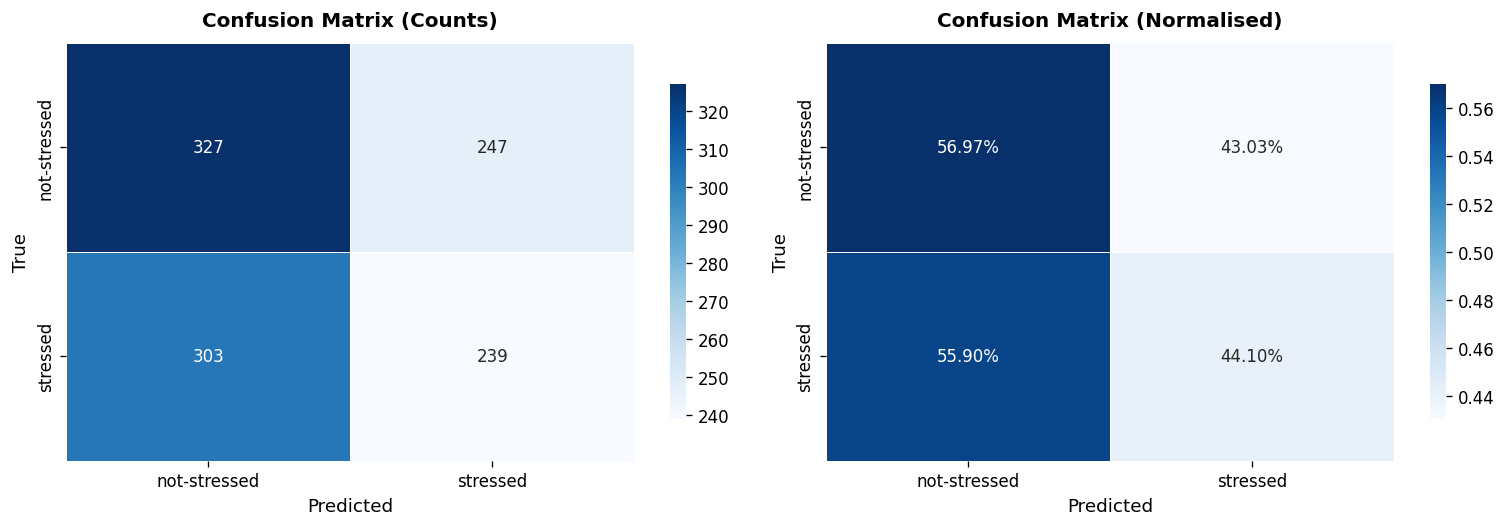

Key findings:
  not-stressed → most confused with stressed     (43.0%)
  stressed     → most confused with not-stressed (55.9%)


In [10]:
cm_total = np.sum([np.array(r['confusion_matrix']) for r in fold_results], axis=0)
cm_norm  = cm_total / (cm_total.sum(axis=1, keepdims=True) + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, data, fmt, title in zip(axes, [cm_total,cm_norm], ['d','.2%'],
                                  ['Counts','Normalised']):
    sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=ax, linewidths=0.5, cbar_kws={'shrink':0.8})
    ax.set_xlabel('Predicted',fontsize=11); ax.set_ylabel('True',fontsize=11)
    ax.set_title(f'Confusion Matrix ({title})', fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR,'confusion_aggregated.png'),dpi=150,bbox_inches='tight')
plt.show()

print('Key findings:')
for i, tname in enumerate(CLASS_NAMES):
    j = np.argmax([cm_norm[i,k] if k!=i else -1 for k in range(NUM_CLASSES)])
    print(f'  {tname:12s} → most confused with {CLASS_NAMES[j]:12s} ({cm_norm[i,j]:.1%})')


---
## 9 · Window vs Session Accuracy


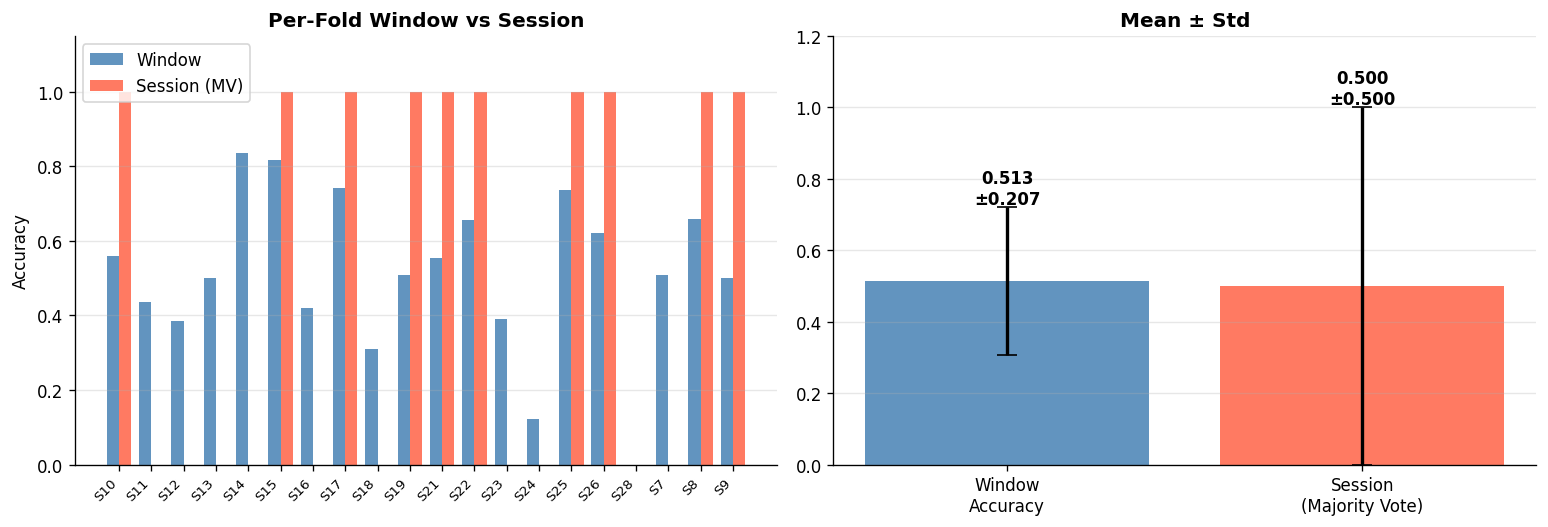

Window  : 0.5132 ± 0.2073
Session : 0.5000 ± 0.5000
Gain    : -0.0132


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
subjects  = [r['subject'] for r in fold_results]
x = np.arange(len(subjects)); w = 0.38
axes[0].bar(x-w/2, win_vals,  w, label='Window',       color='steelblue', alpha=0.85)
axes[0].bar(x+w/2, sess_vals, w, label='Session (MV)', color='tomato',    alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(subjects, rotation=45, ha='right', fontsize=8)
axes[0].set_ylim(0, 1.15); axes[0].set_ylabel('Accuracy')
axes[0].set_title('Per-Fold Window vs Session', fontweight='bold')
axes[0].legend(); axes[0].grid(True, axis='y', alpha=0.3)

means = [np.mean(win_vals), np.mean(sess_vals)]
stds  = [np.std(win_vals),  np.std(sess_vals)]
bars  = axes[1].bar(['Window\nAccuracy','Session\n(Majority Vote)'],
                     means, color=['steelblue','tomato'], alpha=0.85)
axes[1].errorbar(['Window\nAccuracy','Session\n(Majority Vote)'],
                  means, yerr=stds, fmt='none', color='black', capsize=6, lw=2)
for bar,m,s in zip(bars,means,stds):
    axes[1].text(bar.get_x()+bar.get_width()/2, m+s+0.01,
                  f'{m:.3f}\n±{s:.3f}', ha='center', fontweight='bold')
axes[1].set_ylim(0,1.2); axes[1].set_title('Mean ± Std', fontweight='bold')
axes[1].grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR,'window_vs_session.png'),dpi=150,bbox_inches='tight')
plt.show()
print(f'Window  : {np.mean(win_vals):.4f} ± {np.std(win_vals):.4f}')
print(f'Session : {np.mean(sess_vals):.4f} ± {np.std(sess_vals):.4f}')
print(f'Gain    : {np.mean(sess_vals)-np.mean(win_vals):+.4f}')


---
## 10 · Per-Subject Performance


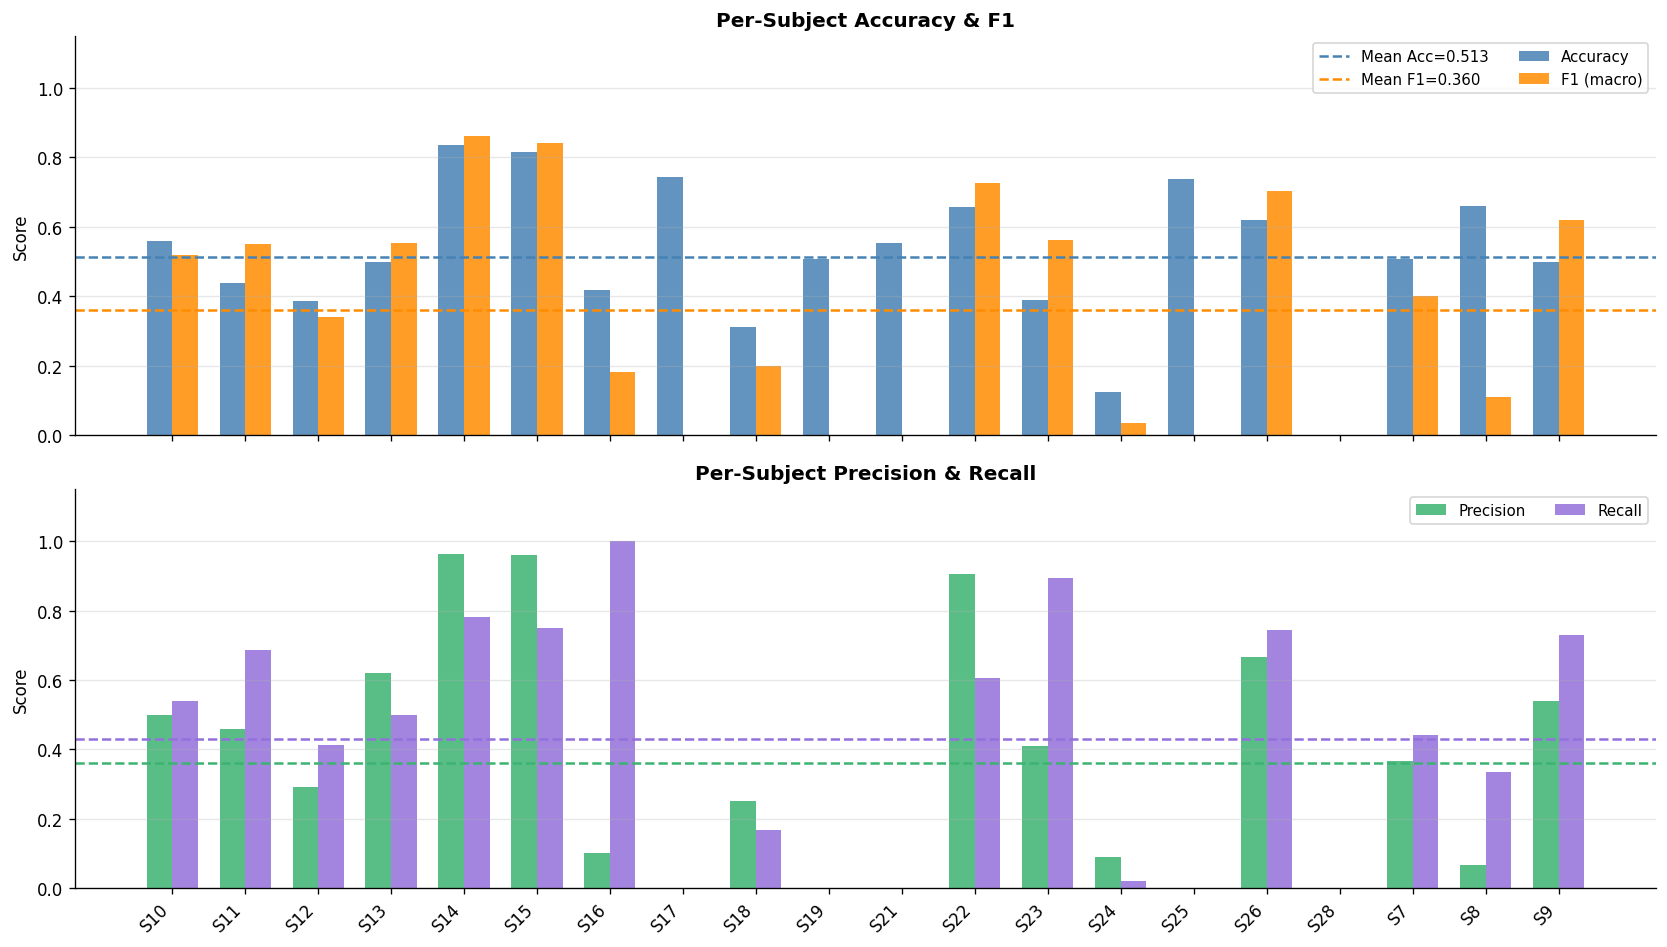

In [12]:
fig, axes = plt.subplots(2,1, figsize=(max(14,len(fold_results)*0.7),8), sharex=True)
accs  = [r['accuracy']  for r in fold_results]
f1s   = [r['f1']        for r in fold_results]
precs = [r['precision'] for r in fold_results]
recs  = [r['recall']    for r in fold_results]
x = np.arange(len(subjects)); w = 0.35

axes[0].bar(x-w/2, accs, w, label='Accuracy',   color='steelblue',    alpha=0.85)
axes[0].bar(x+w/2, f1s,  w, label='F1 (macro)', color='darkorange',   alpha=0.85)
axes[0].axhline(np.mean(accs), color='steelblue', ls='--', lw=1.5,
                 label=f'Mean Acc={np.mean(accs):.3f}')
axes[0].axhline(np.mean(f1s), color='darkorange',  ls='--', lw=1.5,
                 label=f'Mean F1={np.mean(f1s):.3f}')
axes[0].set_ylim(0,1.15); axes[0].set_ylabel('Score')
axes[0].set_title('Per-Subject Accuracy & F1', fontweight='bold')
axes[0].legend(fontsize=9, ncol=2); axes[0].grid(True,axis='y',alpha=0.3)

axes[1].bar(x-w/2, precs, w, label='Precision', color='mediumseagreen', alpha=0.85)
axes[1].bar(x+w/2, recs,  w, label='Recall',    color='mediumpurple',   alpha=0.85)
axes[1].axhline(np.mean(precs),color='mediumseagreen',ls='--',lw=1.5)
axes[1].axhline(np.mean(recs), color='mediumpurple',  ls='--',lw=1.5)
axes[1].set_ylim(0,1.15); axes[1].set_ylabel('Score')
axes[1].set_title('Per-Subject Precision & Recall', fontweight='bold')
axes[1].set_xticks(x); axes[1].set_xticklabels(subjects, rotation=45, ha='right')
axes[1].legend(fontsize=9, ncol=2); axes[1].grid(True,axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR,'per_subject.png'),dpi=150,bbox_inches='tight')
plt.show()


---
## 11 · Training Curves


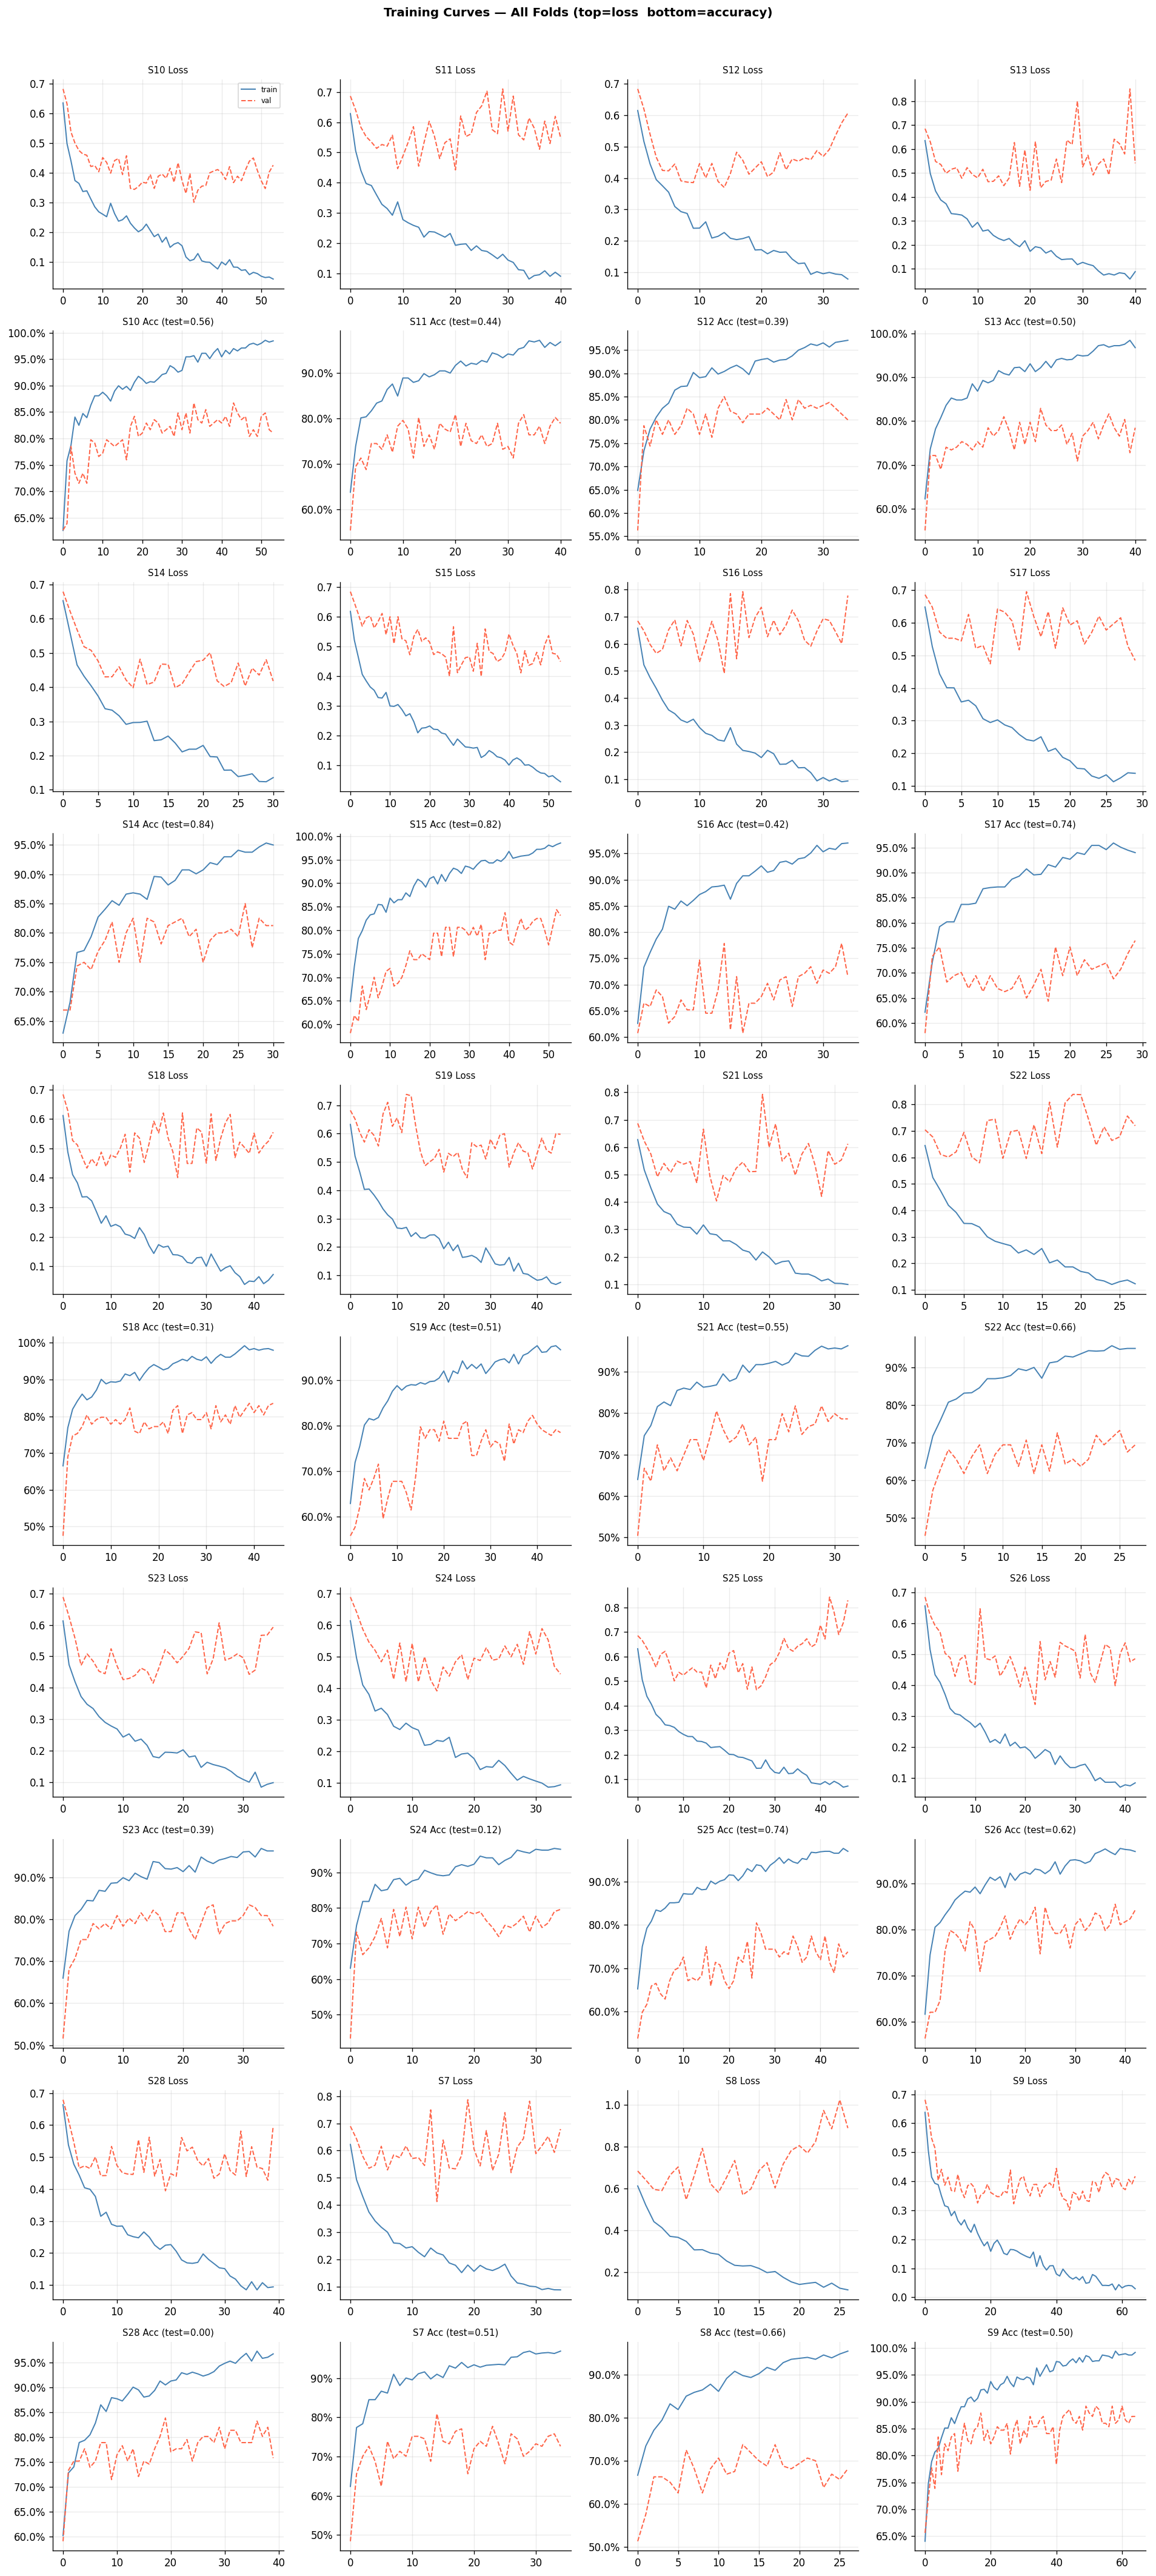

In [13]:
n  = len(fold_results)
nc = min(4, n); nr = (n + nc - 1) // nc
fig, axes = plt.subplots(nr*2, nc, figsize=(4*nc, 3.5*nr*2), squeeze=False)

for idx, r in enumerate(fold_results):
    rl = (idx//nc)*2; ra = rl+1; col = idx%nc
    h  = r['history']
    axes[rl][col].plot(h['train_loss'], color='steelblue', lw=1.2, label='train')
    axes[rl][col].plot(h['val_loss'],   color='tomato',    lw=1.2, ls='--', label='val')
    axes[rl][col].set_title(f"{r['subject']} Loss", fontsize=9)
    axes[rl][col].grid(alpha=0.25)
    if idx == 0: axes[rl][col].legend(fontsize=7)

    axes[ra][col].plot(h['train_acc'], color='steelblue', lw=1.2)
    axes[ra][col].plot(h['val_acc'],   color='tomato',    lw=1.2, ls='--')
    axes[ra][col].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    axes[ra][col].set_title(f"{r['subject']} Acc (test={r['accuracy']:.2f})", fontsize=9)
    axes[ra][col].grid(alpha=0.25)

for idx in range(n, nr*nc):
    axes[(idx//nc)*2][idx%nc].axis('off')
    axes[(idx//nc)*2+1][idx%nc].axis('off')

plt.suptitle('Training Curves — All Folds (top=loss  bottom=accuracy)',
              fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR,'training_curves.png'),dpi=150,bbox_inches='tight')
plt.show()


---
## 12 · Ablation Study

| Variant | Description |
|---------|-------------|
| `cnn_lstm` | Unidirectional LSTM baseline |
| `cnn_bilstm` | Bidirectional — reads forward & backward |
| `cnn_bilstm_attn` | + Self-Attention — focuses best timesteps |

> Runs 3 folds × 3 variants. Change `ABLATION_SUBJECTS` to `unique_subjs` for full study.



Variant: cnn_lstm

Fold 1/3  (Test: S10)
  Train windows : 1057   Test windows :   59
  Accuracy      : 0.4576
  F1-score      : 0.5429  (macro)
  Precision     : 0.4318  (macro)
  Recall        : 0.7308  (macro)
  Per-class F1  : not-stressed=0.333  stressed=0.543
  Session MV    : pred=stressed  true=not-stressed  correct=False
  Epochs run    : 32
  Training time : 7s

Fold 2/3  (Test: S11)
  Train windows : 1052   Test windows :   64
  Accuracy      : 0.2969
  F1-score      : 0.1176  (macro)
  Precision     : 0.1579  (macro)
  Recall        : 0.0938  (macro)
  Per-class F1  : not-stressed=0.416  stressed=0.118
  Session MV    : pred=not-stressed  true=not-stressed  correct=True
  Epochs run    : 35
  Training time : 9s

Fold 3/3  (Test: S12)
  Train windows : 1072   Test windows :   44
  Accuracy      : 0.5227
  F1-score      : 0.2222  (macro)
  Precision     : 0.3000  (macro)
  Recall        : 0.1765  (macro)
  Per-class F1  : not-stressed=0.656  stressed=0.222
  Session MV    : 

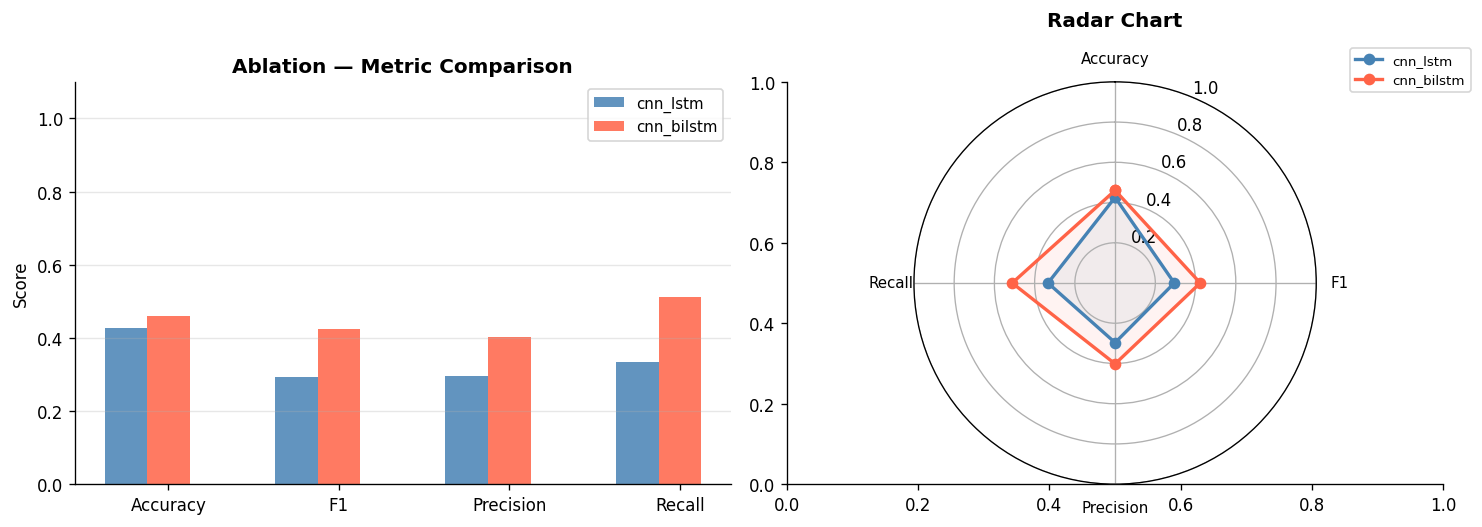

Ablation saved.


In [14]:
ABLATION_SUBJECTS = unique_subjs[:3]
ABLATION_VARIANTS = ['cnn_lstm', 'cnn_bilstm', 'cnn_bilstm_attn']
ablation_results  = {v: [] for v in ABLATION_VARIANTS}

for variant in ABLATION_VARIANTS:
    print(f'\n{"="*50}')
    print(f'Variant: {variant}')
    print(f'{"="*50}')
    for fold_num, subj_idx in enumerate(ABLATION_SUBJECTS, start=1):
        name = subject_labels[subj_idx] if subj_idx < len(subject_labels) else f'subj_{subj_idx}'
        r = train_fold(X, y, groups, subj_idx, name,
                        fold_num, len(ABLATION_SUBJECTS), variant=variant)
        ablation_results[variant].append(r)

# ── Print table ───────────────────────────────────────────────────────────
print('\n' + '='*65)
print(f'{"Model":25s}  {"Accuracy":10s}  {"F1":10s}  {"Precision":10s}  {"Recall"}')
print('-'*65)
ablation_summary = {}
for v in ABLATION_VARIANTS:
    a  = np.mean([r['accuracy']  for r in ablation_results[v]])
    f  = np.mean([r['f1']        for r in ablation_results[v]])
    p  = np.mean([r['precision'] for r in ablation_results[v]])
    rc = np.mean([r['recall']    for r in ablation_results[v]])
    ablation_summary[v] = {'accuracy':a,'f1':f,'precision':p,'recall':rc}
    print(f'{v:25s}  {a:.4f}      {f:.4f}      {p:.4f}      {rc:.4f}')
print('='*65)

# ── Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
m_keys  = ['accuracy','f1','precision','recall']
colors3 = ['steelblue','tomato']
x3      = np.arange(len(m_keys)); w3 = 0.25

for i,(v,col) in enumerate(zip(ABLATION_VARIANTS,colors3)):
    axes[0].bar(x3+(i-1)*w3, [ablation_summary[v][m] for m in m_keys],
                 w3, label=v, color=col, alpha=0.85)
axes[0].set_xticks(x3); axes[0].set_xticklabels([m.title() for m in m_keys])
axes[0].set_ylim(0,1.1); axes[0].set_ylabel('Score')
axes[0].set_title('Ablation — Metric Comparison', fontweight='bold')
axes[0].legend(fontsize=9); axes[0].grid(True, axis='y', alpha=0.3)

# Radar chart
cats   = m_keys; Nc = len(cats)
angles = [n/Nc*2*np.pi for n in range(Nc)]; angles += angles[:1]
ax2    = plt.subplot(122, polar=True)
ax2.set_theta_offset(np.pi/2); ax2.set_theta_direction(-1)
ax2.set_xticks(angles[:-1]); ax2.set_xticklabels([m.title() for m in cats], fontsize=9)
ax2.set_ylim(0, 1)
for v, col in zip(ABLATION_VARIANTS, colors3):
    vals = [ablation_summary[v][m] for m in cats] + [ablation_summary[v][cats[0]]]
    ax2.plot(angles, vals, 'o-', lw=2, label=v, color=col)
    ax2.fill(angles, vals, alpha=0.07, color=col)
ax2.set_title('Radar Chart', fontweight='bold', pad=15)
ax2.legend(loc='upper right', bbox_to_anchor=(1.4,1.1), fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR,'ablation_study.png'),dpi=150,bbox_inches='tight')
plt.show()

pd.DataFrame(ablation_summary).T.to_csv(os.path.join(RESULTS_DIR,'ablation_summary.csv'))
print('Ablation saved.')


---
## 13 · Parameters & Training Time


In [15]:
print('='*58)
print('MODEL EFFICIENCY')
print('='*58)
for v in ABLATION_VARIANTS:
    m   = StressNet(F, NUM_CLASSES, v)
    p   = sum(x.numel() for x in m.parameters())
    del m
    t   = [r['elapsed'] for r in ablation_results[v]]
    print(f'  {v:25s}  params={p:>8,}  avg={np.mean(t):.0f}s/fold')

all_t = [r['elapsed'] for r in fold_results]
print(f'\nMain model full LOSO:')
print(f'  Avg per fold : {np.mean(all_t):.0f}s')
print(f'  Total        : {sum(all_t)/60:.1f} min')
fi = np.argmin(all_t); sl = np.argmax(all_t)
print(f'  Fastest      : {min(all_t):.0f}s ({fold_results[fi]["subject"]})')
print(f'  Slowest      : {max(all_t):.0f}s ({fold_results[sl]["subject"]})')
print('='*58)


MODEL EFFICIENCY
  cnn_lstm                   params= 378,434  avg=9s/fold
  cnn_bilstm                 params= 695,362  avg=11s/fold
  cnn_bilstm_attn            params= 711,874  avg=7s/fold

Main model full LOSO:
  Avg per fold : 10s
  Total        : 3.3 min
  Fastest      : 4s (S14)
  Slowest      : 17s (S9)


---
## 14 · Feature Saliency


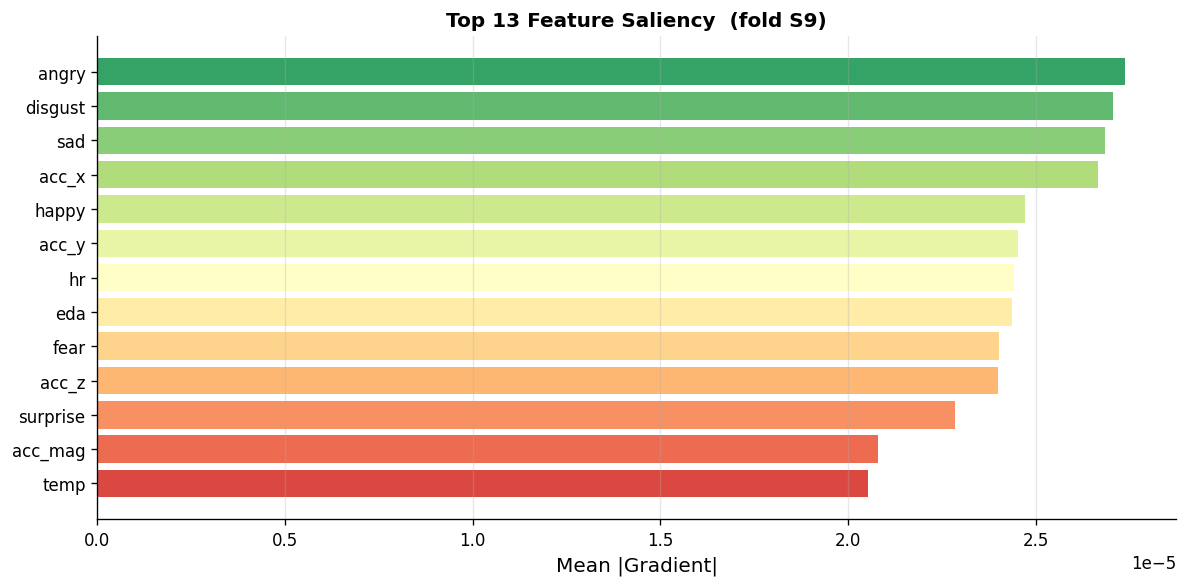

In [18]:
def compute_saliency(model, X_np):
    model.train()
    X_t = torch.from_numpy(X_np).float().to(DEVICE).requires_grad_(True)
    out = model(X_t)
    score = out.max(dim=1).values.mean()
    score.backward()
    return X_t.grad.abs().mean(dim=(0,1)).cpu().numpy()


last_subj = fold_results[-1]['subject']
ckpt_path = os.path.join(CHECKPOINT_DIR, f'{VARIANT}_fold_{last_subj}.pt')

if os.path.exists(ckpt_path):
    ckpt      = torch.load(ckpt_path, map_location=DEVICE)
    sal_model = StressNet(ckpt['n_features'], NUM_CLASSES, ckpt['variant']).to(DEVICE)
    sal_model.load_state_dict(ckpt['model_state'])

    norm = WindowNormalizer()
    X_n  = norm.fit_transform(X)
    sal  = compute_saliency(sal_model, X_n[:min(300,len(X_n))])

    top_k = min(F, 20)
    idx   = np.argsort(sal)[::-1][:top_k]
    names = [feature_names[i] if i < len(feature_names) else f'feat_{i}' for i in idx]

    fig, ax = plt.subplots(figsize=(10,5))
    cmap = plt.cm.RdYlGn_r(np.linspace(0.1,0.9,top_k))
    ax.barh(names[::-1], sal[idx][::-1], color=cmap[::-1], alpha=0.88)
    ax.set_xlabel('Mean |Gradient|', fontsize=12)
    ax.set_title(f'Top {top_k} Feature Saliency  (fold {last_subj})',
                  fontweight='bold')
    ax.grid(True, axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR,'feature_saliency.png'),dpi=150,bbox_inches='tight')
    plt.show()
    del sal_model
else:
    print(f'Checkpoint not found: {ckpt_path}')


---
## 15 · Final Summary Report


In [19]:
print('\n' + '='*60)
print('FINAL REPORT — EmpathicSchool Stress Detection')
print('='*60)
print(f'Dataset')
print(f'  Subjects      : {len(np.unique(groups))}')
print(f'  Total windows : {N}')
print(f'  Features      : {F}  {feature_names}')
print(f'  Window / Stride: {meta["window_sec"]}s / {meta["stride_sec"]}s @ {meta["target_fs"]}Hz')

m = StressNet(F, NUM_CLASSES, VARIANT)
p = sum(x.numel() for x in m.parameters()); del m
print(f'\nModel  ({VARIANT})')
print(f'  Parameters : {p:,}')

print(f'\nLOSO Results  ({total_folds} folds)')
for metric in ['accuracy','f1','precision','recall']:
    vals = [r[metric] for r in fold_results]
    print(f'  {metric.title():12s}: {np.mean(vals):.4f} ± {np.std(vals):.4f}')

print(f'\nMajority Voting ({VOTING_METHOD})')
print(f'  Window  Accuracy : {np.mean(win_vals):.4f} ± {np.std(win_vals):.4f}')
print(f'  Session Accuracy : {np.mean(sess_vals):.4f} ± {np.std(sess_vals):.4f}')
print(f'  Gain             : {np.mean(sess_vals)-np.mean(win_vals):+.4f}')

print(f'\nAblation ({len(ABLATION_SUBJECTS)} folds each)')
print(f'  {"Variant":25s}  {"Accuracy":9s}  F1')
for v in ABLATION_VARIANTS:
    a = ablation_summary[v]
    print(f'  {v:25s}  {a["accuracy"]:.4f}     {a["f1"]:.4f}')

print(f'\nOutputs: {OUTPUT_DIR}')
print('='*60)



FINAL REPORT — EmpathicSchool Stress Detection
Dataset
  Subjects      : 20
  Total windows : 1116
  Features      : 13  ['hr', 'eda', 'temp', 'acc_x', 'acc_y', 'acc_z', 'acc_mag', 'angry', 'disgust', 'fear', 'happy', 'sad', 'surprise']
  Window / Stride: 60s / 30s @ 4Hz

Model  (cnn_bilstm_attn)
  Parameters : 711,874

LOSO Results  (20 folds)
  Accuracy    : 0.5132 ± 0.2073
  F1          : 0.3603 ± 0.3015
  Precision   : 0.3595 ± 0.3269
  Recall      : 0.4300 ± 0.3344

Majority Voting (soft)
  Window  Accuracy : 0.5132 ± 0.2073
  Session Accuracy : 0.5000 ± 0.5000
  Gain             : -0.0132

Ablation (3 folds each)
  Variant                    Accuracy   F1
  cnn_lstm                   0.4257     0.2942
  cnn_bilstm                 0.4604     0.4232
  cnn_bilstm_attn            0.4626     0.2826

Outputs: C:\Users\yomna.000\Downloads\grad\new dataset\EmpathicSchool\outputs
